# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [19]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [20]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [21]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

### [Bài 7] Tác tử để đấu với người

Theo yêu cầu, người chơi đấu với một tác tử tìm kiếm (không chỉ với `random_player`). Ô dưới định nghĩa `alpha_beta_player`:
Minimax có cắt tỉa Alpha-Beta giống Bài 3, luôn chọn nước tối ưu. Kèm hai hàm phụ: `recorded` bọc agent để **ghi lại từng nước đi**,
và `show_log` in chuỗi nước đi sau ván.

In [22]:
# [Bài 7] Tác tử để đấu với người: Minimax có cắt tỉa Alpha-Beta (giống Bài 3), luôn chọn nước tối ưu.
import math

def alpha_beta_search(board, player='x'):
    value, move = max_value_ab(board, player, -math.inf, math.inf)
    return {'move': move, 'value': value}

def max_value_ab(state, player, alpha, beta):
    v = utility(state, player)
    if v is not None:
        return v, None
    v, move = -math.inf, None
    for a in actions(state):
        v2, _ = min_value_ab(result(state, player, a), player, alpha, beta)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            return v, move
    return v, move

def min_value_ab(state, player, alpha, beta):
    v = utility(state, player)
    if v is not None:
        return v, None
    v, move = math.inf, None
    for a in actions(state):
        v2, _ = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha:
            return v, move
    return v, move

def alpha_beta_player(board, player='x'):
    return alpha_beta_search(board, player)['move']

def recorded(agent, name, log):
    """Bọc agent để ghi lại từng nước đi: (tên, quân, ô)."""
    def wrapped(board, player):
        move = agent(board, player)
        log.append((name, player, int(move)))
        return move
    return wrapped

def show_log(log):
    print('Chuỗi nước đi (ô đánh số 0–8 từ trái sang phải, trên xuống dưới):')
    for turn, (name, player, move) in enumerate(log, 1):
        print(f'  {turn}. {name} ({player}) đi ô {move}')

## Start an interactive game as x

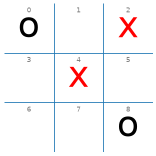

Available actions are: [1, 3, 5, 6, 7]


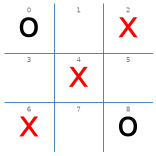

{'x': 1, 'o': 0, 'd': 0}

In [23]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

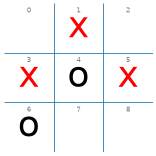

Available actions are: [0, 2, 7, 8]


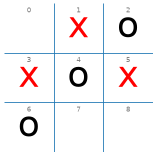

{'x': 0, 'o': 1, 'd': 0}

In [24]:
play(random_player, interactive_player, N = 1, show_final_board = True)

## [Bài 7] Chơi với Alpha-Beta

Chạy từng ô dưới đây. Khi được hỏi, nhập **số ô từ 0 đến 8** (0–2 hàng trên, 3–5 hàng giữa, 6–8 hàng dưới), hoặc **−1** để dừng.
Sau mỗi ván, bàn cuối và **chuỗi nước đi** được in ra để làm bằng chứng ván đấu.

Ô đầu tiên không cần nhập: cho Alpha-Beta tự đấu với chính nó để xem chiến lược khi cả hai chơi tối ưu.

In [25]:
# [Bài 7] Tham khảo (không cần nhập): Alpha-Beta tự đấu với chính nó, để thấy chiến lược khi cả hai chơi tối ưu.
log = []
print(play(recorded(alpha_beta_player, 'Alpha-Beta', log), recorded(alpha_beta_player, 'Alpha-Beta', log), N=1))
show_log(log)

{'x': 0, 'o': 0, 'd': 1}
Chuỗi nước đi (ô đánh số 0–8 từ trái sang phải, trên xuống dưới):
  1. Alpha-Beta (x) đi ô 0
  2. Alpha-Beta (o) đi ô 4
  3. Alpha-Beta (x) đi ô 1
  4. Alpha-Beta (o) đi ô 2
  5. Alpha-Beta (x) đi ô 6
  6. Alpha-Beta (o) đi ô 3
  7. Alpha-Beta (x) đi ô 5
  8. Alpha-Beta (o) đi ô 7
  9. Alpha-Beta (x) đi ô 8


**[Bài 7] Nhận xét Alpha-Beta tự đấu.** Ván **hòa**, đúng như giá trị 0 của bàn trống. Chuỗi nước: x 0, o 4, x 1, o 2, x 6, o 3,
x 5, o 7, x 8.
- x mở ở **góc 0** không phải vì "biết" góc tốt, mà vì mọi nước đầu đều có giá trị 0 và ô 0 được xét đầu tiên.
- Gặp nước mở ở góc, o đi **tâm 4**: đây là nước duy nhất không thua. Các ô 1, 2, 3 được xét trước nhưng đều dẫn tới thua.
- Từ đó mỗi nước đều là **chặn đe dọa**: x đi 1 dọa 0-1-2 → o chặn 2; o có 2-4 dọa 6 → x chặn 6 và dọa 0-3-6 → o chặn 3; ...
  Không bên nào tạo được hai đe dọa cùng lúc nên ván hòa.

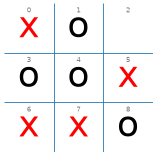

Available actions are: [2]


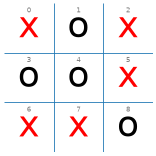

Kết quả: {'x': 0, 'o': 0, 'd': 1}
Chuỗi nước đi (ô đánh số 0–8 từ trái sang phải, trên xuống dưới):
  1. Người (x) đi ô 0
  2. Alpha-Beta (o) đi ô 4
  3. Người (x) đi ô 6
  4. Alpha-Beta (o) đi ô 3
  5. Người (x) đi ô 5
  6. Alpha-Beta (o) đi ô 1
  7. Người (x) đi ô 7
  8. Alpha-Beta (o) đi ô 8
  9. Người (x) đi ô 2


In [26]:
# [Bài 7] Người cầm X (đi trước), Alpha-Beta cầm O. Nhập số ô 0–8 khi được hỏi.
log_x = []
result_x = play(recorded(interactive_player, 'Người', log_x), recorded(alpha_beta_player, 'Alpha-Beta', log_x),
                N=1, show_final_board=True)
print('Kết quả:', result_x)
show_log(log_x)

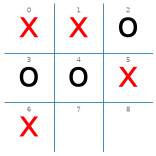

Available actions are: [7, 8]


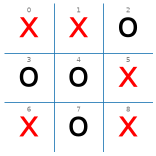

Kết quả: {'x': 0, 'o': 0, 'd': 1}
Chuỗi nước đi (ô đánh số 0–8 từ trái sang phải, trên xuống dưới):
  1. Alpha-Beta (x) đi ô 0
  2. Người (o) đi ô 4
  3. Alpha-Beta (x) đi ô 1
  4. Người (o) đi ô 2
  5. Alpha-Beta (x) đi ô 6
  6. Người (o) đi ô 3
  7. Alpha-Beta (x) đi ô 5
  8. Người (o) đi ô 7
  9. Alpha-Beta (x) đi ô 8


In [27]:
# [Bài 7] Alpha-Beta cầm X (đi trước), người cầm O. Nhập số ô 0–8 khi được hỏi.
log_o = []
result_o = play(recorded(alpha_beta_player, 'Alpha-Beta', log_o), recorded(interactive_player, 'Người', log_o),
                N=1, show_final_board=True)
print('Kết quả:', result_o)
show_log(log_o)

**[Bài 7] Nhận xét ván đấu giữa người và Alpha-Beta.**

- **Ván 1, người cầm X (đi trước), Alpha-Beta cầm O:** kết quả **hòa** (`{'x': 0, 'o': 0, 'd': 1}`).
  Chuỗi nước: người 0 → Alpha-Beta 4 → người 6 → Alpha-Beta 3 → người 5 → Alpha-Beta 1 → người 7 → Alpha-Beta 8 → người 2.
  Người mở ở góc 0, tác tử lấy ngay **tâm 4** (nước duy nhất không thua trước nước mở ở góc). Sau đó tác tử chặn mọi đe dọa:
  người có 0 và 6 dọa cột 0-3-6 → tác tử chặn ở 3; người có 6 và 7 dọa hàng 6-7-8 → tác tử chặn ở 8. Tác tử cũng tự tạo
  đe dọa (3-4-5, rồi 1-4-7) buộc người phải chặn ở 5 và 7. Không bên nào có hai đe dọa cùng lúc nên ván kín bàn và hòa.
- **Ván 2, Alpha-Beta cầm X (đi trước), người cầm O:** kết quả **hòa** (`{'x': 0, 'o': 0, 'd': 1}`).
  Chuỗi nước: Alpha-Beta 0 → người 4 → Alpha-Beta 1 → người 2 → Alpha-Beta 6 → người 3 → Alpha-Beta 5 → người 7 → Alpha-Beta 8.
  Người đáp nước mở góc bằng tâm 4 và chặn đúng mọi đe dọa (2 chặn 0-1-2, 3 chặn 0-3-6); tác tử cũng chặn đe dọa 3-4-5 của người ở ô 5, nên ván hòa. Chuỗi nước
  này **trùng hoàn toàn** với ván Alpha-Beta tự đấu ở trên: người đã đi đúng nước tối ưu ở mọi lượt.
- Ở hai ván đấu với `random_player` (hai ô gốc phía trên), người **thắng cả hai** khi cầm X và khi cầm O, vì Random không biết chặn.
  Ngược lại, với Alpha-Beta, người chơi đúng hết cũng chỉ **hòa**.

**Chiến lược của tác tử:**
- **Không bao giờ thua:** Alpha-Beta tìm tới cuối ván nên luôn chọn nước tối ưu. Người chơi tốt nhất chỉ hòa; đi sai một nước thì
  tác tử tận dụng ngay để thắng.
- **Luôn chặn đe dọa:** khi người có hai quân thẳng hàng với ô thứ ba trống, tác tử chặn ngay, vì không chặn thì giá trị là −1.
- **Tận dụng sai lầm:** nếu người để hở, tác tử tạo **hai đe dọa cùng lúc** (fork) mà người chỉ chặn được một. Hai ván trên
  không có tình huống này vì người không đi sai nước nào.
- **Không ưu tiên thắng nhanh** (cơ chế chung, không xuất hiện trong hai ván hòa trên): mọi nước thắng đều có giá trị +1 như nhau, tác tử lấy nước được xét trước (chỉ số ô nhỏ hơn),
  nên có lúc không thắng ngay mà đi nước khác vẫn chắc thắng ở lượt sau.
- **Nước mở:** cầm X thì mở ở góc 0; cầm O mà người mở ở góc thì tác tử lấy tâm 4 (nước duy nhất không thua).